<a href="https://colab.research.google.com/github/YashVardhanSingh216/Deep-Learning/blob/main/30_WeightInitialization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('ushape.csv')
df.head()

,X,Y,class
0,0.0316,0.9870,0.0
1,2.1200,-0.0462,1.0
2,0.8820,-0.0758,0.0
3,-0.0551,-0.0373,1.0
4,0.8300,-0.5390,1.0


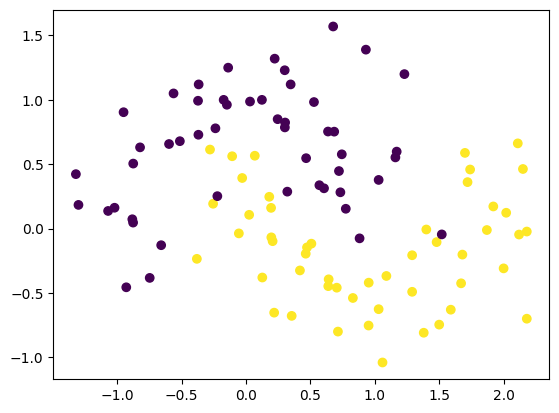

In [3]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [4]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

XAVIER INITIALIZATION:-

In [5]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [9]:
model = Sequential()

model.add(Dense(10,activation='tanh', input_dim = 2))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.get_weights()

[array([[ 0.59973985, -0.02923286, -0.19738007,  0.5188181 , -0.29104102,
          0.19822472,  0.6730204 ,  0.08962041, -0.0986051 , -0.29546306],
        [-0.01855439,  0.10479575,  0.1929068 ,  0.38970524, -0.6822509 ,
         -0.6738521 , -0.3243087 ,  0.14480913,  0.2029733 , -0.01661426]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-4.95110422e-01,  3.06355834e-01, -2.47164160e-01,
          5.31970739e-01, -5.02145886e-02, -2.81462759e-01,
          2.97409832e-01,  4.09992993e-01, -3.69669616e-01,
          5.04460096e-01],
        [-1.28714502e-01, -1.37680739e-01,  3.26377988e-01,
          1.18064344e-01,  2.71630883e-02,  4.87586856e-02,
         -3.26956093e-01,  1.47629499e-01, -3.35424304e-01,
          2.16407716e-01],
        [ 3.99755359e-01,  4.31948483e-01, -4.04925942e-01,
          5.33125877e-01, -1.27710789e-01,  5.04947186e-01,
         -4.32901531e-01, -2.34692812e-01,  2.85677850e-01,
         -1.2504473

In [16]:
initial_weights = model.get_weights()

for i in range(0, len(initial_weights), 2):

    fan_in = initial_weights[i].shape[0]
    fan_out = initial_weights[i].shape[1]

    std = np.sqrt(2/(fan_in + fan_out))

    initial_weights[i] = np.random.randn(
        *initial_weights[i].shape
    ) * std

model.set_weights(initial_weights)

In [17]:
model.get_weights()

[array([[ 0.433874  ,  0.1953252 , -0.4080311 , -0.2804817 ,  0.57613224,
          0.05324537,  0.43603384, -0.37328458, -0.41240948, -0.4321901 ],
        [ 0.7663692 , -0.24430797, -0.05766964, -0.14625186,  0.05018261,
          0.228241  , -0.11522511, -0.25961593, -0.22728866,  0.3931931 ]],
       dtype=float32),
 array([-0.09740793,  0.5572533 ,  0.07568417,  0.07460865,  0.07237906,
         0.10099474, -0.18777075, -0.3671164 ,  0.24030332,  0.34733203],
       dtype=float32),
 array([[ 0.03165977,  0.00554592,  0.05733834,  0.49161074,  0.40975404,
          0.53335685, -0.6478235 , -0.42244297,  0.44242427, -0.0625324 ],
        [ 0.02862155,  0.51041394, -0.43820244, -0.14797781, -0.04974217,
         -0.11557903, -0.26732907, -0.69334686,  0.16946776,  0.06901923],
        [ 0.0860663 , -0.08620101,  0.49896565, -0.01040996,  0.57897615,
          0.49200872, -0.13720661,  0.38690248,  0.15357257,  0.03634089],
        [-0.19805549, -0.22390662,  0.15143025,  0.56371284, 

In [18]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 122ms/step - accuracy: 0.2250 - loss: 0.7772 - val_accuracy: 0.2000 - val_loss: 0.7667
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.2500 - loss: 0.7601 - val_accuracy: 0.3500 - val_loss: 0.7463
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3125 - loss: 0.7454 - val_accuracy: 0.3500 - val_loss: 0.7276
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3750 - loss: 0.7302 - val_accuracy: 0.4000 - val_loss: 0.7108
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4375 - loss: 0.7164 - val_accuracy: 0.5000 - val_loss: 0.6952
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.4875 - loss: 0.7046 - val_accuracy: 0.6000 - val_loss: 0.6803
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5375 - loss: 0.6925 - val_accuracy: 0.7000 - val_loss: 0.6663
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5875 - loss: 0.6816 - val_accuracy: 0.8500 - val_loss

In [19]:
model.get_weights()

[array([[ 0.51463616,  0.09335214, -0.31613916, -0.21089533,  0.43757772,
          0.13654225,  0.36195326, -0.2707409 , -0.41150314, -0.43602318],
        [ 0.808626  , -0.14017498,  0.09938914, -0.28905243, -0.11771748,
          0.11587686, -0.25325027, -0.39216506, -0.1752914 ,  0.5808929 ]],
       dtype=float32),
 array([-0.16791335,  0.5666038 ,  0.15645711,  0.08855923, -0.00259743,
         0.147818  , -0.25351903, -0.39955634,  0.32110858,  0.38092777],
       dtype=float32),
 array([[ 0.08487362, -0.04067179,  0.04548769,  0.3417565 ,  0.5646565 ,
          0.70351815, -0.76086414, -0.57353723,  0.26301524, -0.17554064],
        [-0.07218177,  0.49485913, -0.36919534, -0.07964616, -0.02218783,
         -0.16528091, -0.20091152, -0.62036055,  0.16045591,  0.14713064],
        [ 0.19204654, -0.09258553,  0.4278134 , -0.07858597,  0.63902736,
          0.5595956 , -0.23784716,  0.30534533,  0.05475382, -0.0413483 ],
        [-0.13936912, -0.22293156,  0.09266209,  0.61989367, 

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


<Axes: >

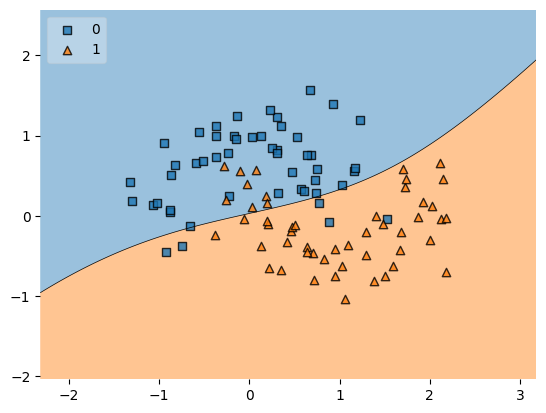

In [20]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)

HE INITIALIZATOION:-

In [21]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2,kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
initial_weights = model.get_weights()

In [23]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - accuracy: 0.5000 - loss: 0.9025 - val_accuracy: 0.5000 - val_loss: 0.8385
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5000 - loss: 0.8564 - val_accuracy: 0.5000 - val_loss: 0.8055
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5250 - loss: 0.8200 - val_accuracy: 0.5000 - val_loss: 0.7741
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5125 - loss: 0.7859 - val_accuracy: 0.5000 - val_loss: 0.7451
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5125 - loss: 0.7517 - val_accuracy: 0.4500 - val_loss: 0.7187
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5250 - loss: 0.7227 - val_accuracy: 0.5000 - val_loss: 0.6945
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5250 - loss: 0.6968 - val_accuracy: 0.5000 - val_loss: 0.6718
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5125 - loss: 0.6733 - val_accuracy: 0.5000 - val_loss

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


<Axes: >

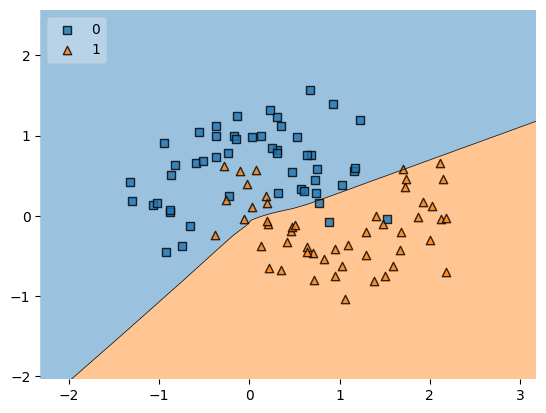

In [24]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)